# D3 · Gradient and Spin Echo Pulse Sequences

**Part:** D – Contrast · **Reading time:** ~60 min · **Pass 1 overview:** [P1.4 Contrast and Image Quality](../pass1_big_picture/P1.4_Contrast_and_Image_Quality.ipynb) · **Refreshers you may want:** [RM2 Complex numbers and rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [RM1 ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb)

**Why this chapter matters.** Almost every MRI sequence is built on one of two "echo" mechanisms. A **gradient echo** is quick and simple but sees every field imperfection ($T_2^*$). A **spin echo** uses an extra 180° pulse to *undo* the dephasing caused by static field variations, giving pure $T_2$ contrast and robustness near air and metal – at the price of time and RF power. Understanding exactly what a 180° pulse does to the phase of each isochromat (and what it cannot undo) explains $T_2$ vs $T_2^*$, multi-echo trains (CPMG, fast spin echo), stimulated echoes, and many artefacts.

## Learning goals

1. Describe how various types of MRI contrast are created
    * Describe the difference between gradient-echo and spin-echo contrast
2. Understand the most popular pulse sequences and their acronyms
    * Identify gradient-echo and spin-echo pulse sequences
3. Identify artefacts and how to mitigate them
    * Understand the effects of off-resonance and $T_2^*$ on contrast
4. *(added)* Derive the phase-reversal argument for why a 180° pulse refocuses static off-resonance and why a gradient echo does not
5. *(added)* Explain the Hahn echo, the CPMG echo train (and why its phase choice makes it robust), and stimulated echoes

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $M_{xy}=M_x+iM_y$ | transverse magnetization (rotating frame) | normalized | |
| $M_z$, $M_0$ | longitudinal / equilibrium magnetization | normalized | $M_0=1$ |
| $\phi_j(t)$ | phase of isochromat $j$ | rad | |
| $\Delta f_j$ | off-resonance of isochromat $j$ (field inhomogeneity, susceptibility, chemical shift) | Hz | 0–100s of Hz |
| $\tau$ | time between excitation and refocusing pulse ($TE=2\tau$) | s | |
| $TE$, $TR$ | echo time, repetition time | s | |
| $T_2$, $T_2^*$, $T_2'$ | transverse, effective transverse, inhomogeneity time constants | s | $1/T_2^*=1/T_2+1/T_2'$ |
| $\Gamma$ | half-width of a Lorentzian off-resonance distribution ($1/T_2'=2\pi\Gamma$) | Hz | |
| $\theta$, $\theta_{ref}$ | flip angle; refocusing flip angle | rad (°) | 90°, 180° |
| $G_x(t)$ | readout gradient | T/m | 10–40 mT/m |
| $k_x(t)=\bar\gamma\int_0^tG_x(\tau')d\tau'$ | k-space position | m⁻¹ | |
| $x_j$ | position of isochromat $j$ | m | |
| $\bar\gamma$, $\gamma$ | gyromagnetic ratio (Hz/T), (rad s⁻¹ T⁻¹) | | 42.58 MHz/T |
| $t_{esp}$ | echo spacing in a multi-echo train | s | 5–15 ms |
| $ETL$ | echo-train length (number of echoes per excitation) | – | 1–256 |
| $TM$ | mixing time between 2nd and 3rd pulse (stimulated echo) | s | |
| $T_1$ | longitudinal relaxation time | s | |
| $SAR$ | specific absorption rate (RF heating) | W/kg | limit 2 W/kg whole body (normal mode) |
| $s(t)$ | voxel / object signal | a.u. | |

> **⚠️ Common confusion:** $\tau$ here is half the echo time; elsewhere $\tau$ is used as an integration variable (we write $\tau'$ then).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. The gradient-echo pulse sequence (GE or GRE)

The building block of a **gradient-echo** sequence is an RF excitation pulse followed by the imaging gradients. A complete 2D imaging sequence ([C1 Pulse Sequence](../pass2_deep_dive/C1_Pulse_Sequence.ipynb)):

![Gradient echo pulse sequence: RF, slice-select gradient Gz, phase-encode Gy, readout Gx, and data acquisition](../images/pulse_sequence-diagram-all.png)

It is called a "gradient echo" because the frequency-encoding gradient on $G_x$ first **dephases** the magnetization (negative prephasing lobe) and then **rephases** it (positive readout lobe); at the echo time the area under $G_x$ is zero and the signal peaks. Another name is "gradient-recalled echo" (GRE). The simplified diagram:

![Simplified gradient echo pulse sequence](../images/pulse_sequence-diagram-simple.png)

### Why a gradient echo forms

With a gradient $G_x$ switched on, an isochromat at position $x_j$ that is also off-resonant by $\Delta f_j$ accumulates the phase (left-handed precession convention, see [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb))

$$\phi_j(t)=-2\pi\,k_x(t)\,x_j\;-\;2\pi\,\Delta f_j\,t,\qquad k_x(t)=\bar\gamma\int_0^tG_x(\tau')\,d\tau'.$$

*In words:* the first term is the phase from the gradient, which depends on position and on the gradient *area* so far; the second is the phase from off-resonance, which simply grows with time,
where $k_x$ is the k-space position (cycles/m, [F2 K-space](../pass2_deep_dive/F2_K-space.ipynb)), $x_j$ the position (m), $\Delta f_j$ the off-resonance (Hz).

The gradient term can be **reversed**: making $G_x$ negative and then positive brings $k_x$ back to zero, and at that moment the gradient phase vanishes for every position – the **gradient echo**. The off-resonance term **cannot** be reversed by gradients: $-2\pi\Delta f_jt$ keeps growing in the same direction. So at the gradient echo, $\phi_j(TE)=-2\pi\Delta f_j\,TE$, and the voxel signal is reduced by dephasing:

$$S_{GE}\propto M_0\,e^{-TE/T_2^*}.$$

*In words:* the gradient echo undoes the dephasing we caused deliberately, but not the dephasing caused by field inhomogeneity, so its amplitude decays with $T_2^*$.

The simulation below uses `mt.bloch_simulate` with 400 isochromats spread over 1 cm in $x$: a prephasing lobe −10 mT/m for 2.5 ms, then a readout lobe +10 mT/m for 5 ms (echo at 5 ms), once with a perfect field and once with a Lorentzian off-resonance spread (Γ = 15 Hz).

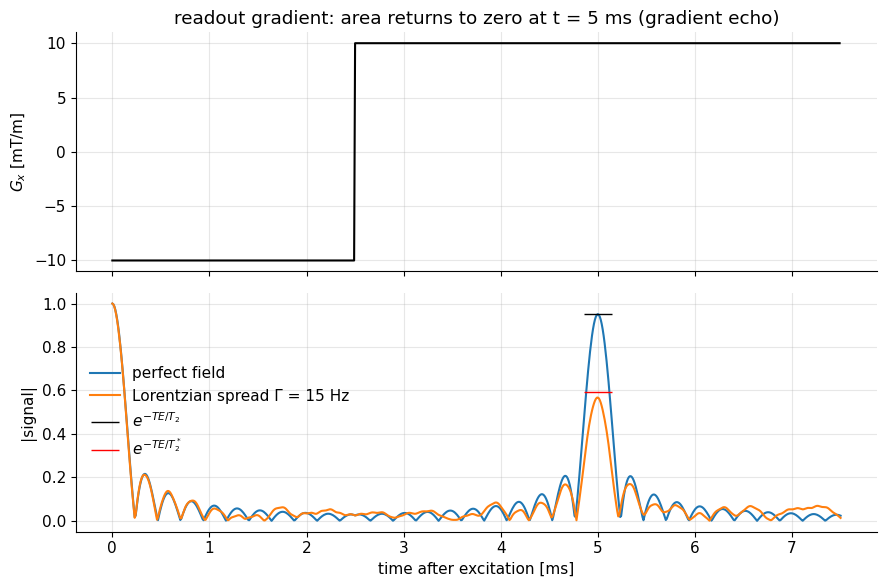

In [2]:
# Gradient echo: dephase with -G, rephase with +G; off-resonance is NOT refocused
Ns = 400
x = np.linspace(-0.005, 0.005, Ns)                 # positions [m] (1 cm object)
r = np.stack([x, 0 * x, 0 * x], axis=1)
dt = 10e-6
G = 10e-3                                          # 10 mT/m
Gx = np.concatenate([-G * np.ones(250), G * np.ones(500)])   # 2.5 ms prephaser, 5 ms readout
Gw = np.stack([Gx, 0 * Gx, 0 * Gx], axis=1)
rng = np.random.default_rng(0)
Gamma = 15.0
dfs = {"perfect field": 0.0 * x, f"Lorentzian spread Γ = {Gamma:.0f} Hz": Gamma * rng.standard_cauchy(Ns)}
T2 = 0.1
fig, axs = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
t = np.arange(len(Gx) + 1) * dt
axs[0].plot(t[:-1] * 1e3, Gx * 1e3, "k"); axs[0].set_ylabel("$G_x$ [mT/m]")
axs[0].set_title("readout gradient: area returns to zero at t = 5 ms (gradient echo)")
for name, df in dfs.items():
    _, M = mt.bloch_simulate(G=Gw, r=r, dt=dt, M_init=[1, 0, 0], T2=T2, df=df)   # start just after excitation
    s = np.mean(M[:, :, 0] + 1j * M[:, :, 1], axis=1)
    axs[1].plot(t * 1e3, np.abs(s), label=name)
TE = 5e-3
axs[1].plot(TE * 1e3, np.exp(-TE / T2), "k_", ms=20, label="$e^{-TE/T_2}$")
axs[1].plot(TE * 1e3, np.exp(-TE / T2 - 2 * np.pi * Gamma * TE), "r_", ms=20, label="$e^{-TE/T_2^*}$")
axs[1].set_xlabel("time after excitation [ms]"); axs[1].set_ylabel("|signal|"); axs[1].legend()
plt.tight_layout(); plt.show()

*Interpretation:* the signal vanishes during the prephaser (positions are dephased by the gradient) and comes back as an echo exactly when the gradient area is zero. With a perfect field the echo reaches the $T_2$ value; with off-resonance it only reaches the lower $T_2^*$ value – the gradient echo cannot undo it.

## 2. Refocusing off-resonance with a spin echo

The effect of static off-resonance can be reversed by applying a 180° **refocusing pulse** some time after the excitation. The 180° pulse **inverts the phase** each isochromat has accumulated, after which the continuing off-resonance precession *cancels* that phase.

### The phase-reversal argument (derivation)

Take one isochromat $j$ with static off-resonance $\Delta f_j$. Excite at $t=0$ (all phases equal, set to 0 for simplicity). Then:

1. **Before the 180°** ($0<t<\tau$): $\phi_j(t)=-2\pi\Delta f_j\,t$. Just before the pulse, $\phi_j(\tau^-)=-2\pi\Delta f_j\tau$.
2. **The 180° pulse about $x$** maps $(M_x,M_y,M_z)\to(M_x,-M_y,-M_z)$. For the complex transverse magnetization this is $M_{xy}=M_x+iM_y\;\to\;M_x-iM_y=M_{xy}^*$: **complex conjugation**, i.e. $\phi\to-\phi$. So $\phi_j(\tau^+)=+2\pi\Delta f_j\tau$.
3. **After the pulse** the isochromat keeps precessing at the same $\Delta f_j$: $\phi_j(t)=+2\pi\Delta f_j\tau-2\pi\Delta f_j(t-\tau)=-2\pi\Delta f_j\,(t-2\tau)$.
4. At $t=2\tau$: $\phi_j=0$ **for every $j$**, whatever $\Delta f_j$ is. All isochromats are back in phase: the **spin echo**, at $TE=2\tau$.

*In words:* the 180° pulse swaps "ahead" and "behind". The fast isochromats that had run ahead are put behind by the same amount, and since they still run fast, they catch up exactly when the same time $\tau$ has passed again.

> **🧭 Intuition (race-track analogy):** runners of different speeds start together. At time $\tau$ everyone turns around and runs back at their own speed. At $2\tau$ they all arrive at the start line simultaneously – the faster ones went further but also come back faster.

**About $y$ instead of $x$:** a 180° about $y$ maps $(M_x,M_y)\to(-M_x,M_y)$, i.e. $M_{xy}\to-M_{xy}^*$, phase $\phi\to\pi-\phi$. The same steps give $\phi_j(2\tau)=\pi$ for all $j$: the echo forms just as well, only along a different axis (a global phase, harmless for one echo – but it matters for echo trains, Section 6).

**What must hold:** $\Delta f_j$ must be the **same before and after** the pulse. That is true for magnet imperfections, susceptibility fields and chemical shift (static), but not for

* the random, fluctuating microscopic fields that cause $T_2$ → **$T_2$ decay is not refocused**;
* spins that **move** (diffusion, flow) through a field gradient during $2\tau$ → signal loss (the basis of diffusion imaging);
* time-varying fields (eddy currents, field drift, motion).

Consequently

$$S_{SE}\propto M_0\,e^{-TE/T_2}.$$

*In words:* the spin-echo amplitude decays with $T_2$ alone, because the static part of the dephasing ($T_2'$) has been undone.

The next cell shows this for five isochromats with different $\Delta f_j$: their phase versus time, for a gradient echo (no 180°) and a spin echo (180° about $x$ at $\tau$ = 20 ms). We use `mt.bloch_simulate` with a short hard 180° pulse.

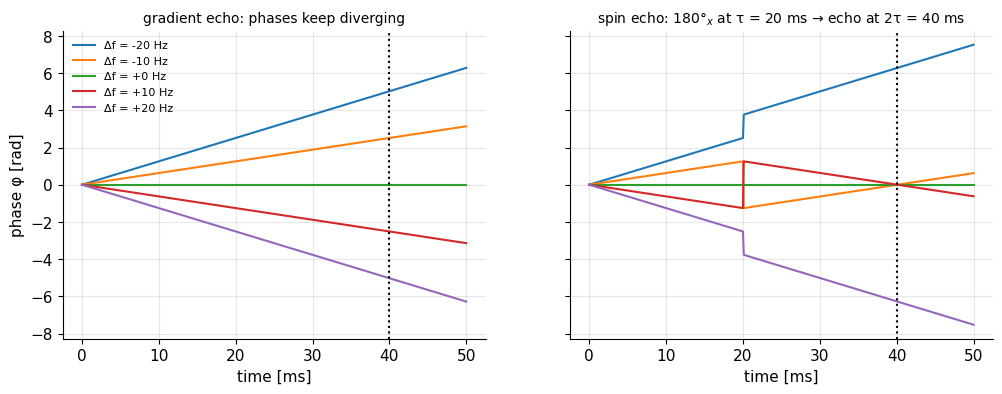

In [3]:
# Phase evolution of 5 isochromats: gradient echo vs spin echo (180x at tau = 20 ms)
dfj = np.array([-20, -10, 0, 10, 20.0])              # off-resonance [Hz]
dt, tau = 0.1e-3, 0.020
n_tau = int(round(tau / dt)); trf = dt               # 180 pulse in one step of 0.1 ms
b1_180 = mt.b1_for_flip(np.pi, trf)
B1_se = np.zeros(2 * n_tau + 100, complex); B1_se[n_tau] = b1_180   # pulse at tau
B1_ge = np.zeros_like(B1_se)
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, B1, title in [(axs[0], B1_ge, "gradient echo: phases keep diverging"),
                      (axs[1], B1_se, "spin echo: 180°$_x$ at τ = 20 ms → echo at 2τ = 40 ms")]:
    t, M = mt.bloch_simulate(B1=B1, dt=dt, M_init=[1, 0, 0], df=dfj)   # start along x after excitation
    phase = np.unwrap(np.angle(M[:, :, 0] + 1j * M[:, :, 1]), axis=0)
    for j in range(len(dfj)):
        ax.plot(t * 1e3, phase[:, j], label=f"Δf = {dfj[j]:+.0f} Hz")
    ax.axvline(40, color="k", ls=":"); ax.set_xlabel("time [ms]"); ax.set_title(title, fontsize=10)
axs[0].set_ylabel("phase φ [rad]"); axs[0].legend(fontsize=8); plt.show()

*Interpretation:* without refocusing, the phases fan out linearly forever; the 180° pulse mirrors them ($\phi\to-\phi$) and the unchanged precession then walks all of them back to zero at exactly 40 ms.

### Voxel animations from the original

This is most easily seen in the original's voxel decay animations (64 isochromats, $T_2$ = 80 ms):

![Voxel signal decay with spin echo, no off-resonance](../images/t2star-spinecho_no_off-resonance.gif)

**Spin echo with no off-resonance, $T_2$ = 80 ms**

![Voxel signal decay with spin echo, mild off-resonance](../images/t2star-spinecho_mild_off-resonance.gif)

**Spin echo with mild off-resonance, $T_2$ = 80 ms**

![Voxel signal decay with spin echo, severe off-resonance](../images/t2star-spinecho_severe_off-resonance.gif)

**Spin echo with severe off-resonance, $T_2$ = 80 ms**

The spin echo makes no difference when there is no off-resonance. Can you identify when the 180° refocusing pulse was applied? It is when $M_{xy}$ (the dashed $M_y$ curve) flips its sign. Compare with the versions without refocusing in [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb):

![Voxel signal decay without spin echo, severe off-resonance](../images/t2star_severe_off-resonance.gif)

**Gradient echo (no refocusing), severe off-resonance**

The next cell is the Python port of `t2star_spinecho_illustration.m` with the spin-echo flag on: as in the MATLAB code, the 180° pulse is applied at $t=T_{max}/3$ ≈ 26.7 ms by inverting $M_y$ (an ideal 180° about $x$), so the echo appears at ≈ 53.3 ms.

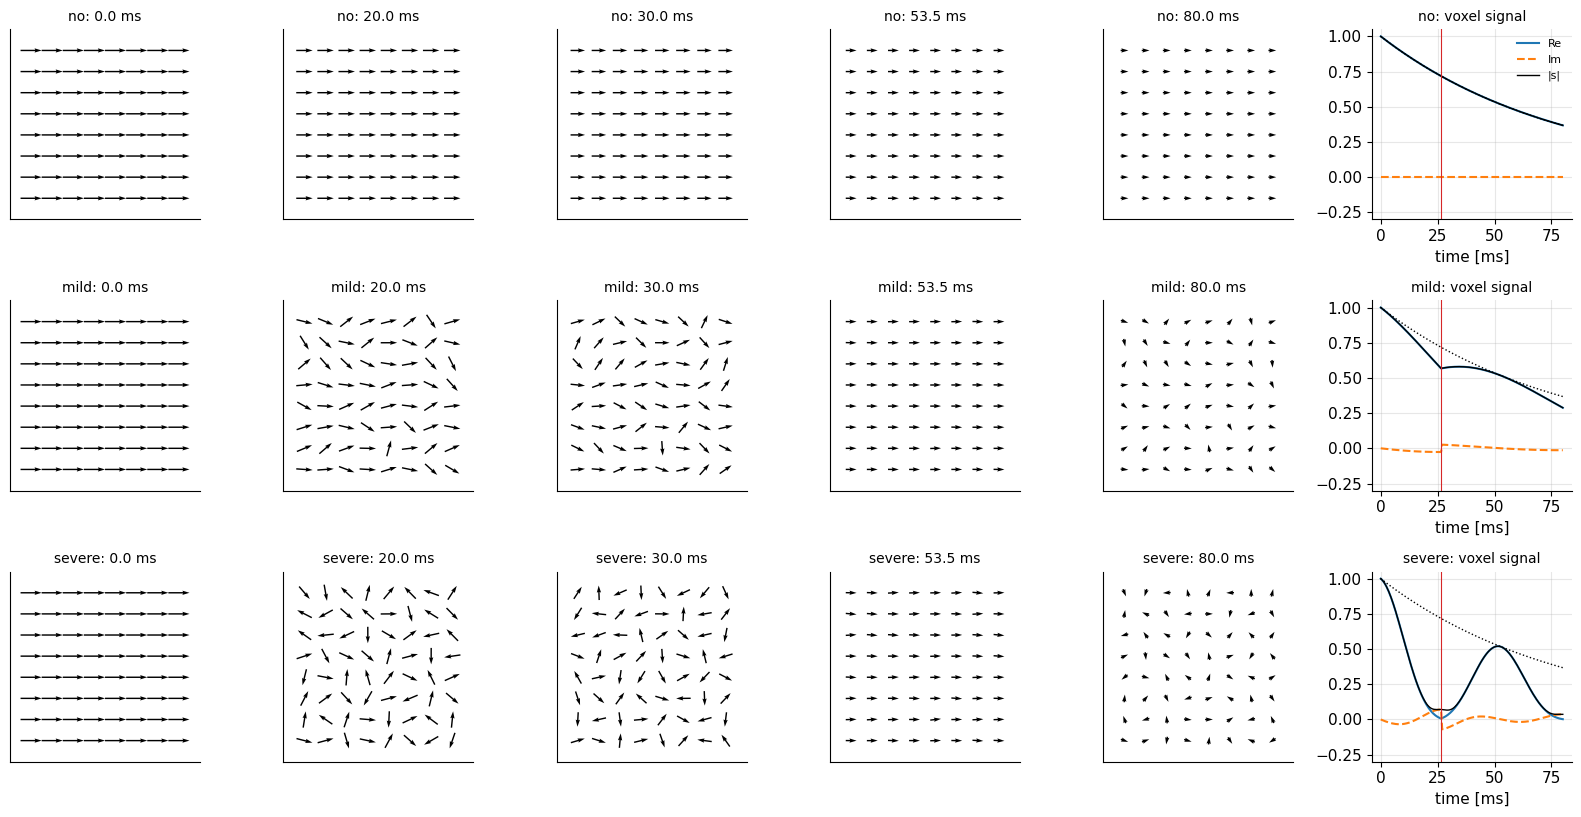

In [4]:
# Port of t2star_spinecho_illustration.m with spinecho_flag = 1 (snapshots instead of a GIF)
B0, T2 = 1.5, 0.080
rng = np.random.default_rng(0)
n_side = 8; Ns = n_side**2
dt, Tmax = 0.5e-3, 0.080
N = int(round(Tmax / dt)); n180 = int(round(N / 3))
z = rng.standard_normal(Ns)
cases = {"no": 0.0, "mild": 0.07e-6, "severe": 0.25e-6}       # std of dB0/B0
snap_ms = [0, 20, 30, 53.5, 80]
gx, gy = np.meshgrid(np.arange(n_side), np.arange(n_side))
fig, axs = plt.subplots(3, 6, figsize=(16, 8.3))
for row, (name, rel) in enumerate(cases.items()):
    df = mt.GAMMA_BAR * B0 * rel * z
    _, Ma = mt.bloch_simulate(n_steps=n180, dt=dt, M_init=[1, 0, 0], T2=T2, df=df)
    Mb0 = Ma[-1].copy(); Mb0[:, 1] *= -1; Mb0[:, 2] *= -1          # ideal 180 deg about x: My -> -My
    _, Mb = mt.bloch_simulate(n_steps=N - n180, dt=dt, M_init=Mb0, T2=T2, df=df)
    M = np.concatenate([Ma, Mb[1:]]); t = np.arange(M.shape[0]) * dt
    Mxy = M[:, :, 0] + 1j * M[:, :, 1]
    for col, ts in enumerate(snap_ms):
        k = min(int(round(ts * 1e-3 / dt)), len(t) - 1); m = Mxy[k].reshape(n_side, n_side)
        ax = axs[row, col]
        ax.quiver(gx - m.real / 2, gy - m.imag / 2, m.real, m.imag, angles="xy", scale_units="xy", scale=1)
        ax.set_xlim(-1, n_side); ax.set_ylim(-1, n_side); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{name}: {ts:.1f} ms", fontsize=10)
    s = Mxy.mean(axis=1); ax = axs[row, 5]
    ax.plot(t * 1e3, s.real, label="Re"); ax.plot(t * 1e3, s.imag, "--", label="Im"); ax.plot(t * 1e3, np.abs(s), "k", lw=1, label="|s|")
    ax.plot(t * 1e3, np.exp(-t / T2), "k:", lw=1); ax.axvline(n180 * dt * 1e3, color="C3", lw=0.8)
    ax.set_ylim(-0.3, 1.05); ax.set_xlabel("time [ms]"); ax.set_title(f"{name}: voxel signal", fontsize=10)
    if row == 0: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

*Interpretation:* after the 180° (red line) the arrows that had fanned out gather again and at ≈ 53 ms they all point the same way: the voxel signal is back on the $T_2$ curve (dotted), however severe the off-resonance was. After the echo they dephase again.

## 3. $T_2$ versus $T_2^*$ envelopes

If we keep the receiver open during the whole spin-echo experiment, we see: a **free induction decay** (FID) right after the 90° that decays with $T_2^*$; then, around the echo, a signal that **grows** (rephasing) and **decays** (dephasing) again, each with the $T_2'$ rate, under an overall $T_2$ envelope. For a Lorentzian distribution (Section 2.3 of [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb)) this is exactly

$$|s(t)|=M_0\,e^{-t/T_2}\,e^{-|t-TE|/T_2'}\qquad(t>\tau).$$

*In words:* the $T_2$ factor depends on the total time since excitation (irreversible), the $T_2'$ factor on the time distance to the echo (reversible),
where $TE=2\tau$ and $1/T_2'=2\pi\Gamma$.

If we repeat the experiment with different TE values, the echo peaks trace out the $T_2$ curve, while gradient echoes at the same times trace out the $T_2^*$ curve.

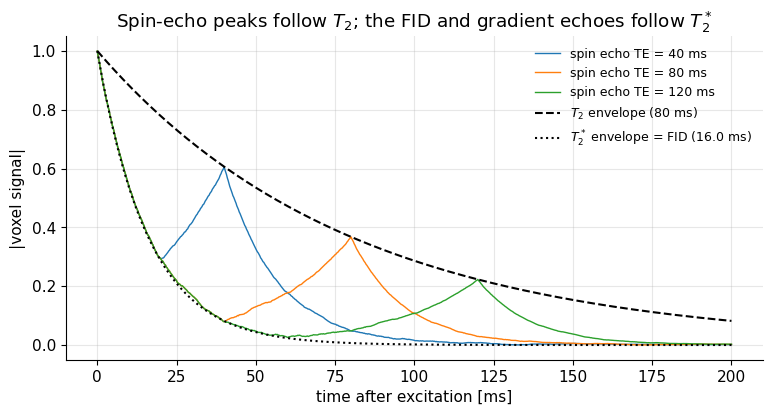

In [5]:
# FID, spin echo and envelopes: Lorentzian off-resonance, T2 = 80 ms, T2' = 20 ms
T2, Gamma = 0.080, 1 / (2 * np.pi * 0.020)            # Gamma chosen so that T2' = 20 ms
T2p = 1 / (2 * np.pi * Gamma); T2s = 1 / (1 / T2 + 1 / T2p)
rng = np.random.default_rng(2)
df = Gamma * rng.standard_cauchy(4000)
t = np.linspace(0, 0.2, 801)
def se_signal(t, tau):
    """voxel signal of a 90-tau-180x experiment, phasor sum over isochromats (ideal instantaneous pulses)"""
    ph = np.where(t[:, None] < tau, -2 * np.pi * df * t[:, None], -2 * np.pi * df * (t[:, None] - 2 * tau))
    return np.abs(np.exp(1j * ph).mean(axis=1)) * np.exp(-t / T2)
plt.figure(figsize=(9, 4.2))
for tau in [0.02, 0.04, 0.06]:
    plt.plot(t * 1e3, se_signal(t, tau), lw=1, label=f"spin echo TE = {2*tau*1e3:.0f} ms")
plt.plot(t * 1e3, np.exp(-t / T2), "k--", label=f"$T_2$ envelope ({T2*1e3:.0f} ms)")
plt.plot(t * 1e3, np.exp(-t / T2s), "k:", label=f"$T_2^*$ envelope = FID ({T2s*1e3:.1f} ms)")
plt.xlabel("time after excitation [ms]"); plt.ylabel("|voxel signal|"); plt.legend(fontsize=9)
plt.title("Spin-echo peaks follow $T_2$; the FID and gradient echoes follow $T_2^*$"); plt.show()

*Interpretation:* every echo peak touches the $T_2$ envelope; the rise into and fall out of each echo has the fast $T_2'$ time constant; and the FID (the signal a gradient echo would sample) follows the much lower $T_2^*$ curve.

## 4. Exploring refocusing: the drcmr.dk exercises in Python

To simulate and visualize off-resonance with various refocusing pulses, the original suggests:

* Visit http://drcmr.dk/BlochSimulator/, Scene: *Inhomogeneity*
* Apply 90ₓ hard, then 180ᵧ hard – what happens to the dephasing spins?
* Apply 90ₓ hard, then 180ₓ hard – the 180° is about a different axis. Is there still a spin echo?
* Apply 90ₓ hard, then repeated 180s – can multiple spin echoes be created?

Below are the same experiments with `mt.bloch_simulate` (helper functions `pulse` and `free` defined in the cell; 2000 isochromats with uniform off-resonance ±100 Hz, $T_2$ = 100 ms, hard pulses of 50 µs). In our convention a 90° pulse about $x$ (real $b_1$) tips $M$ from $z$ to $+y$; a pulse about $y$ has $b_1$ multiplied by $i$.

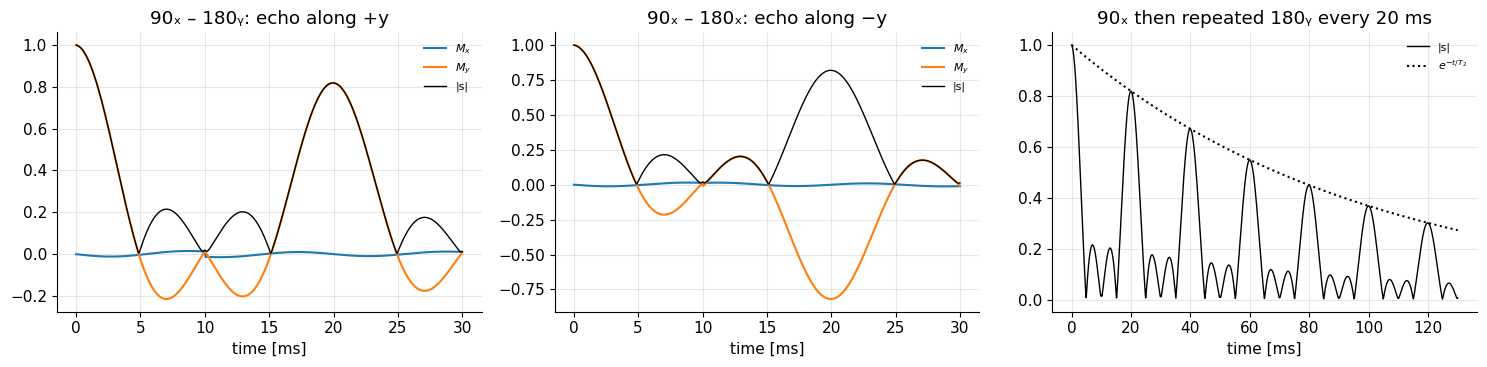

In [6]:
# Helpers: hard pulse with given flip & phase, and free precession, both via mt.bloch_simulate
TRF = 50e-6
def pulse(M, theta, phase, df, T1=np.inf, T2=np.inf):
    """hard RF pulse: flip angle theta [rad] about the axis at angle `phase` from x in the xy-plane"""
    b1 = mt.b1_for_flip(theta, TRF) * np.exp(1j * phase)
    return mt.bloch_simulate(B1=np.array([b1]), dt=TRF, M_init=M, df=df, T1=T1, T2=T2, return_all=False)[1]

def free(M, duration, df, n=1, T1=np.inf, T2=np.inf):
    """free precession + relaxation; n>1 returns the whole time course (n steps)"""
    t, Mt = mt.bloch_simulate(n_steps=n, dt=duration / n, M_init=M, df=df, T1=T1, T2=T2, return_all=(n > 1))
    return (t, Mt) if n > 1 else Mt

rng = np.random.default_rng(3)
Ns = 2000; df = rng.uniform(-100, 100, Ns); T2 = 0.1
M_eq = np.tile([0.0, 0.0, 1.0], (Ns, 1))
tau = 0.010
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (phase_ref, name) in zip(axs[:2], [(np.pi / 2, "90ₓ – 180ᵧ"), (0.0, "90ₓ – 180ₓ")]):
    M = pulse(M_eq, np.pi / 2, 0.0, df)
    t1, Ma = free(M, tau, df, n=200, T2=T2)
    M = pulse(Ma[-1], np.pi, phase_ref, df)
    t2, Mb = free(M, 2 * tau, df, n=400, T2=T2)
    t = np.concatenate([t1, tau + t2[1:]]); Mt = np.concatenate([Ma, Mb[1:]])
    s = Mt[:, :, 0].mean(1) + 1j * Mt[:, :, 1].mean(1)
    ax.plot(t * 1e3, s.real, label="$M_x$"); ax.plot(t * 1e3, s.imag, label="$M_y$"); ax.plot(t * 1e3, abs(s), "k", lw=1, label="|s|")
    ax.set_title(f"{name}: echo along {'+y' if phase_ref else '−y'}"); ax.set_xlabel("time [ms]"); ax.legend(fontsize=8)
# repeated 180y pulses: multiple echoes
M = pulse(M_eq, np.pi / 2, 0.0, df); tt, ss = [], []
t0 = 0.0
tc, Mc = free(M, tau, df, n=100, T2=T2); tt.append(tc); ss.append(Mc)
M = Mc[-1]; t0 = tau
for k in range(6):
    M = pulse(M, np.pi, np.pi / 2, df)
    tc, Mc = free(M, 2 * tau, df, n=200, T2=T2); tt.append(t0 + tc[1:]); ss.append(Mc[1:]); M = Mc[-1]; t0 += 2 * tau
t = np.concatenate(tt); Mt = np.concatenate(ss)
axs[2].plot(t * 1e3, np.abs(Mt[:, :, 0].mean(1) + 1j * Mt[:, :, 1].mean(1)), "k", lw=1, label="|s|")
axs[2].plot(t * 1e3, np.exp(-t / T2), "k:", label="$e^{-t/T_2}$")
axs[2].set_title("90ₓ then repeated 180ᵧ every 20 ms"); axs[2].set_xlabel("time [ms]"); axs[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

*Interpretation:* both 180° axes give a full echo at 20 ms; with 180ᵧ the echo forms along $+y$ (where the magnetization started), with 180ₓ along $-y$ – the phase-reversal argument predicted exactly this ($\phi\to\pi-\phi$ vs $\phi\to-\phi$). Repeated 180° pulses create an echo train whose peaks follow $e^{-t/T_2}$.

### How much refocusing does a non-180° pulse give?

A rotation by $\theta_{ref}$ about $x$ acting on transverse magnetization can be written (exercise: use $M_x$, $M_y$ components)

$$M_{xy}^+=\cos^2\!\tfrac{\theta_{ref}}{2}\,M_{xy}^-\;+\;\sin^2\!\tfrac{\theta_{ref}}{2}\,\big(M_{xy}^-\big)^*\;+\;(\text{term}\propto M_z^-).$$

*In words:* the pulse splits the transverse magnetization into a part that keeps its phase (it continues to dephase – no echo) and a phase-conjugated part (which refocuses); only the fraction $\sin^2(\theta_{ref}/2)$ forms the spin echo,
where $\theta_{ref}$ is the refocusing flip angle. 180° gives 1, 90° gives ½ – which is why Hahn's original experiment with two 90°-ish pulses still produced echoes. The next cell checks this.

<details><summary><b>📐 Derivation (optional)</b></summary>

For a right-handed rotation by angle $\alpha$ about $x$: $M_x'=M_x$, $M_y'=M_y\cos\alpha-M_z\sin\alpha$, $M_z'=M_y\sin\alpha+M_z\cos\alpha$ (the left-handed MRI convention only changes the sign of the $M_z$ term). Write $M_x=\tfrac12(M_{xy}+M_{xy}^*)$, $iM_y=\tfrac12(M_{xy}-M_{xy}^*)$:
$$M_{xy}'=M_x+iM_y\cos\alpha-iM_z\sin\alpha=\tfrac{1+\cos\alpha}{2}M_{xy}+\tfrac{1-\cos\alpha}{2}M_{xy}^*-iM_z\sin\alpha,$$
and $\tfrac{1+\cos\alpha}{2}=\cos^2\tfrac{\alpha}{2}$, $\tfrac{1-\cos\alpha}{2}=\sin^2\tfrac{\alpha}{2}$.

</details>

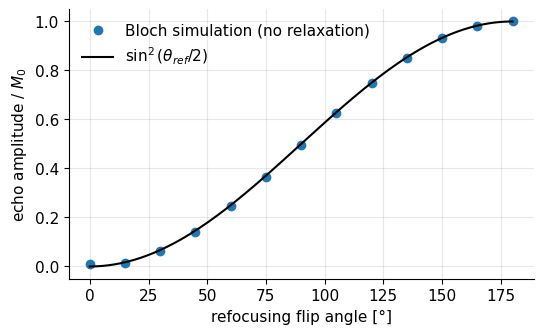

In [7]:
# Echo amplitude vs refocusing flip angle: simulation vs sin^2(theta/2)
angles = np.arange(0, 181, 15)
amp = []
for a in angles:
    M = pulse(M_eq, np.pi / 2, 0.0, df); M = free(M, tau, df)
    M = pulse(M, np.deg2rad(a), 0.0, df); M = free(M, tau, df)
    amp.append(abs(M[:, 0].mean() + 1j * M[:, 1].mean()))
plt.figure(figsize=(6, 3.5))
plt.plot(angles, amp, "o", label="Bloch simulation (no relaxation)")
th = np.linspace(0, 180, 200); plt.plot(th, np.sin(np.deg2rad(th) / 2)**2, "k", label=r"$\sin^2(\theta_{ref}/2)$")
plt.xlabel("refocusing flip angle [°]"); plt.ylabel("echo amplitude / $M_0$"); plt.legend(); plt.show()

*Interpretation:* the simulated echo amplitudes lie on $\sin^2(\theta_{ref}/2)$: a 120° refocusing pulse still gives 75 % of the full echo, which is why scanners often use reduced refocusing angles to save RF power.

## 5. The spin-echo pulse sequence (SE)

The building block of a **spin-echo** sequence has an additional 180° refocusing pulse between excitation and data acquisition, timed so that the spin echo coincides with the gradient echo of the readout:

![Spin echo pulse sequence](../images/pulse_sequence-diagram-spinecho-all.png)

It is called a "spin echo" because the spins themselves (their off-resonance phases) are refocused at the echo time TE. (The original text mistakenly says "gradient echo" here.) Note two details in the diagram: the readout prephaser has the **same** sign as the readout lobe, because the 180° pulse also inverts the phase from the prephaser; and the slice-select gradient during the 180° is often surrounded by **crusher** gradients, which dephase any signal that the imperfect 180° creates by itself (its own "FID") but cancel for the refocused magnetization.

The simplified diagram:

![Simplified spin echo pulse sequence](../images/pulse_sequence-diagram-spinecho-simple.png)

Because of the refocusing, a spin-echo sequence gives pure $T_2$ contrast; including $T_1$ recovery ([D1](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb)):

$$S_{SE}=M_0\,\big(1-e^{-TR/T_1}\big)\,e^{-TE/T_2}\qquad(TE\ll TR).$$

*In words:* TR sets the $T_1$ weighting and TE the $T_2$ weighting; $T_2'$ effects are gone at the echo,
where $M_0$ is proton density, $T_1$, $T_2$ the tissue time constants. This is `mt.spin_echo_signal`.

### Imaging consequence: GRE vs SE near a susceptibility source

We put a small "air pocket" next to the tissue phantom: around it, $T_2'$ becomes very short (we model a Lorentzian width $\Gamma(\vec r)$ that falls off like $1/r^3$, the decay of a dipole field). The gradient echo multiplies by $e^{-2\pi\Gamma TE}$; the spin echo does not.

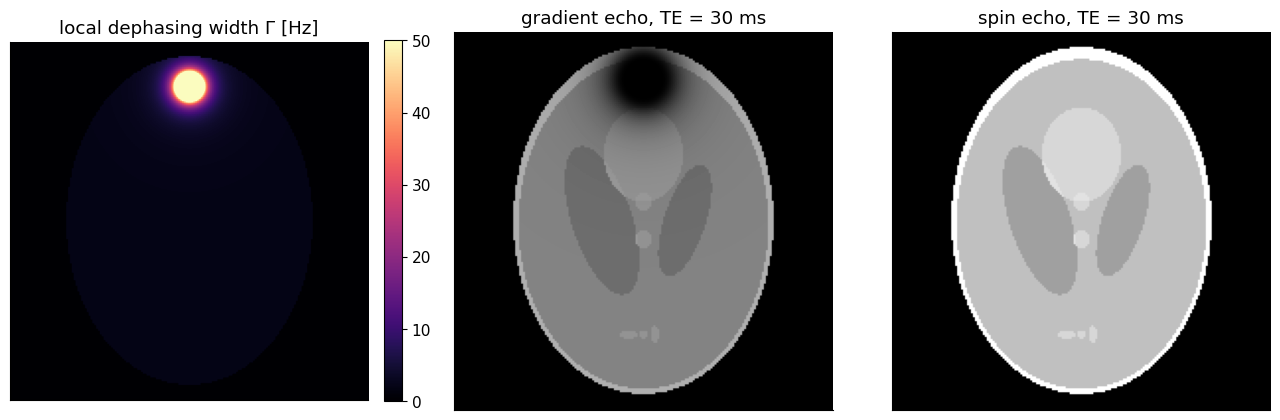

In [8]:
# GRE vs SE images of the tissue phantom with a local susceptibility source (simple voxel-wise model)
ph = mt.tissue_phantom(192)
M0, T1m, T2m, lab = ph["M0"], ph["T1"], ph["T2"], ph["labels"]
yy, xx = np.mgrid[1:-1:192j, -1:1:192j]
rr = np.hypot(xx - 0.0, yy - 0.75)                     # source near the top of the "head"
Gam = np.clip(60 * (0.08 / np.maximum(rr, 1e-3))**3, 0, 500) + 2.0   # Lorentzian half-width [Hz] (2 Hz background)
TR, TE = 2.0, 0.030
se = mt.spin_echo_signal(TE, TR, T1m, T2m, M0) * (lab > 0)
ge = se * np.exp(-2 * np.pi * Gam * TE)                # 90-degree GRE with same TR/TE: extra T2' decay
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
mt.show_image(Gam * (lab > 0), ax=axs[0], title="local dephasing width Γ [Hz]", cmap="magma", vmax=50, colorbar=True)
mt.show_image(ge, ax=axs[1], title=f"gradient echo, TE = {TE*1e3:.0f} ms", vmin=0, vmax=se.max())
mt.show_image(se, ax=axs[2], title=f"spin echo, TE = {TE*1e3:.0f} ms", vmin=0, vmax=se.max())
plt.tight_layout(); plt.show()

*Interpretation:* the gradient-echo image shows a dark signal void around the source (like the frontal lobes above the sinuses, or around dental work), plus a slight overall darkening from the 2 Hz background width; the spin-echo image is unaffected. (A real image also shows geometric distortion from the off-resonance during readout – see [I2 Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb).)

## 6. Echo trains: Hahn, Carr–Purcell and CPMG (added)

* **Hahn echo** (E. Hahn, *Phys. Rev.* 80, 580, 1950): the first spin echoes, observed with two RF pulses (90°–τ–90°-like); one excitation, one echo.
* **Carr–Purcell (CP)** (*Phys. Rev.* 94, 630, 1954): 90°ₓ followed by a train of 180° pulses at $\tau, 3\tau, 5\tau,\dots$, giving echoes at $2\tau, 4\tau,\dots$ (echo spacing $t_{esp}=2\tau$). Short spacing also reduces the signal loss from diffusion in background gradients.
* **Carr–Purcell–Meiboom–Gill (CPMG)** (*Rev. Sci. Instrum.* 29, 688, 1958): the same train, but the refocusing pulses are applied about the axis **along which the magnetization lies after excitation** (90°ₓ → magnetization along $y$ → 180°ᵧ pulses). Meiboom and Gill showed this makes the train robust to errors in the 180° flip angle.

**Why CPMG is robust:** a refocusing pulse about the same axis as the magnetization leaves magnetization *along that axis* unchanged even if the flip angle is wrong (a rotation does not move vectors on its axis). Errors only affect the perpendicular component, and in CPMG they cancel on every second echo instead of accumulating. In CP, the refocusing axis is perpendicular to the magnetization, so every flip-angle error accumulates.

The simulation below runs CP and CPMG with ideal (180°) and imperfect (160°, 130°) refocusing pulses – as happens with $B_1^+$ inhomogeneity at 3 T – and plots echo amplitudes divided by $e^{-t/T_2}$ (so that 1 = perfect refocusing).

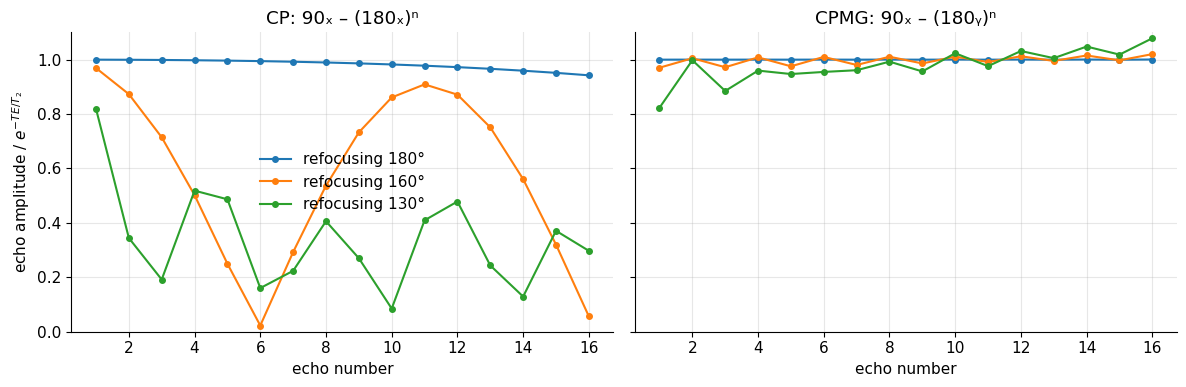

In [9]:
# CP vs CPMG echo trains with imperfect refocusing flip angles
rng = np.random.default_rng(1)
Ns = 2000; df = rng.uniform(-200, 200, Ns); T2 = 0.1
esp, n_echo = 0.010, 16
M_eq = np.tile([0.0, 0.0, 1.0], (Ns, 1))
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, ref_phase) in zip(axs, [("CP: 90ₓ – (180ₓ)ⁿ", 0.0), ("CPMG: 90ₓ – (180ᵧ)ⁿ", np.pi / 2)]):
    for ref in [180, 160, 130]:
        M = pulse(M_eq, np.pi / 2, 0.0, df); M = free(M, esp / 2, df, T2=T2)
        amps = []
        for n in range(n_echo):
            M = pulse(M, np.deg2rad(ref), ref_phase, df); M = free(M, esp / 2, df, T2=T2)
            amps.append(abs(M[:, 0].mean() + 1j * M[:, 1].mean())); M = free(M, esp / 2, df, T2=T2)
        te = esp * np.arange(1, n_echo + 1)
        ax.plot(np.arange(1, n_echo + 1), np.array(amps) / np.exp(-te / T2), "o-", ms=4, label=f"refocusing {ref}°")
    ax.set_title(name); ax.set_xlabel("echo number"); ax.set_ylim(0, 1.1)
axs[0].set_ylabel(r"echo amplitude / $e^{-TE/T_2}$"); axs[0].legend(); plt.tight_layout(); plt.show()

*Interpretation:* with perfect 180° pulses both trains are identical. With 160° or 130° pulses, CP echoes collapse and oscillate wildly, while CPMG echoes settle to a stable, nearly full amplitude after a small even/odd wiggle. That is why every clinical fast-spin-echo sequence uses the CPMG phase condition. (The stable CPMG amplitude is partly made of **stimulated echoes**, Section 7, which mix $T_1$ into the decay – a correction needed for accurate $T_2$ mapping.)

### Fast spin echo (RARE / TSE / FSE)

Acquiring a *different* phase-encoding line at each echo of a CPMG train gives **fast spin echo** (Hennig's RARE; vendor names TSE – Siemens/Philips, FSE – GE): ETL lines per TR instead of one, so scans are ETL times faster. The contrast is set mainly by the echo that acquires the centre of k-space, the **effective TE**. See [H2 Fast Imaging Pulse Sequences](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb).

![Simplified fast spin echo pulse sequence](../images/pulse_sequence-diagram-fastspinecho-simple.png)

The echoes of a CPMG train can also be used directly to **measure $T_2$**: fit $\ln S_n = \ln S_0 - n\,t_{esp}/T_2$.

true T2 = 85 ms, fitted T2 = 86.0 ms


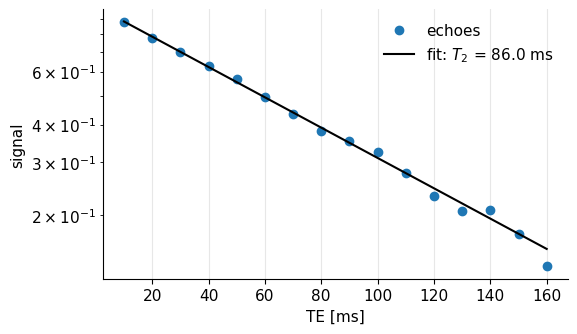

In [10]:
# T2 mapping from a (perfect) CPMG train with noise: log-linear fit
T2_true, S0, esp = 0.085, 1.0, 0.010
n = np.arange(1, 17); te = n * esp
rng = np.random.default_rng(5)
S = S0 * np.exp(-te / T2_true) + rng.normal(0, 0.01, n.size)
slope, icpt = np.polyfit(te, np.log(np.abs(S)), 1, w=np.abs(S))   # weight by amplitude (noise in log grows at small S)
print(f"true T2 = {T2_true*1e3:.0f} ms, fitted T2 = {-1/slope*1e3:.1f} ms")
plt.figure(figsize=(6, 3.5)); plt.semilogy(te * 1e3, S, "o", label="echoes")
plt.semilogy(te * 1e3, np.exp(icpt + slope * te), "k", label=f"fit: $T_2$ = {-1/slope*1e3:.1f} ms")
plt.xlabel("TE [ms]"); plt.ylabel("signal"); plt.legend(); plt.show()

*Interpretation:* on a log scale the echo amplitudes lie on a straight line whose slope is $-1/T_2$.

## 7. Stimulated echoes (brief)

With **three** RF pulses, more echoes appear. Take three 90° pulses at $0$, $\tau$ and $\tau+TM$:

* The second pulse creates a normal (Hahn) spin echo at $2\tau$.
* It also stores *half* of the dephased magnetization along $z$, with its phase pattern "printed" into $M_z$ (a modulation $\propto\cos\phi_j$). During the **mixing time** TM this stored magnetization does not precess and relaxes with $T_1$, not $T_2$.
* The third pulse brings the stored pattern back to the transverse plane, and it rephases a time $\tau$ later: the **stimulated echo** (STE) at $2\tau+TM$, with amplitude $\tfrac12M_0\,e^{-2\tau/T_2}\,e^{-TM/T_1}$ (for 90° pulses).
* Further spin echoes appear from pulse pairs (1,3), (2,3) and from refocusing the first echo.

Stimulated echoes are used in STEAM spectroscopy and some diffusion methods (long diffusion time with only $T_1$ decay during TM), and they inevitably contribute to every echo of a train with non-180° pulses (the CPMG plot above). The **extended phase graph** formalism keeps track of all these pathways (Hennig 1988; Weigel 2015).

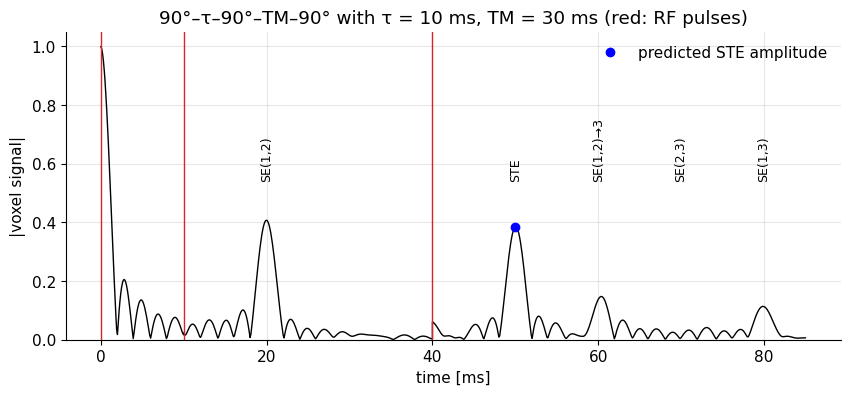

In [11]:
# Three 90-degree pulses: spin echoes and the stimulated echo (time-resolved voxel signal)
rng = np.random.default_rng(4)
Ns = 3000; df = rng.uniform(-250, 250, Ns)             # broad spread -> narrow echoes
T1, T2 = 0.5, 0.1
tau, TM = 0.010, 0.030
M = pulse(np.tile([0.0, 0, 1], (Ns, 1)), np.pi / 2, 0, df, T1, T2)
segs, times = [], []
for (dur, t0, next_pulse) in [(tau, 0, True), (TM, tau, True), (0.045, tau + TM, False)]:
    t, Mt = free(M, dur, df, n=int(dur / 0.1e-3), T1=T1, T2=T2)
    segs.append(Mt); times.append(t0 + t); M = Mt[-1]
    if next_pulse:
        M = pulse(M, np.pi / 2, 0, df, T1, T2)
t = np.concatenate(times); Mt = np.concatenate(segs)
s = np.abs(Mt[:, :, 0].mean(1) + 1j * Mt[:, :, 1].mean(1))
plt.figure(figsize=(10, 4)); plt.plot(t * 1e3, s, "k", lw=1)
for tp in [0, tau, tau + TM]:
    plt.axvline(tp * 1e3, color="C3", lw=1)
labels = {"SE(1,2)": 2 * tau, "STE": 2 * tau + TM, "SE(1,2)→3": 2 * TM, "SE(2,3)": tau + 2 * TM, "SE(1,3)": 2 * (tau + TM)}
for name, tl in labels.items():
    plt.annotate(name, (tl * 1e3, 0.55), ha="center", fontsize=9, rotation=90)
plt.plot((2 * tau + TM) * 1e3, 0.5 * np.exp(-2 * tau / T2) * np.exp(-TM / T1), "bo", label="predicted STE amplitude")
plt.xlabel("time [ms]"); plt.ylabel("|voxel signal|"); plt.ylim(0, 1.05); plt.legend()
plt.title(f"90°–τ–90°–TM–90° with τ = {tau*1e3:.0f} ms, TM = {TM*1e3:.0f} ms (red: RF pulses)")
plt.show()

*Interpretation:* besides the FID after the first pulse, echoes appear at the predicted times (the (2,3) echo at 70 ms is very weak with these parameters); the stimulated echo at $2\tau+TM$ = 50 ms reaches the predicted $\tfrac12e^{-2\tau/T_2}e^{-TM/T_1}$ (blue dot), and the Hahn echo from two 90° pulses has half the amplitude of a 180°-refocused echo, as $\sin^2(45°)=\tfrac12$ predicted.

## 8. Gradient echo vs spin echo: summary and engineering trade-offs

| | Gradient echo (GRE) | Spin echo (SE, FSE) |
|---|---|---|
| refocusing | gradients only | 180° RF pulse(s) + gradients |
| decay at the echo | $T_2^*$ | $T_2$ |
| sensitivity to $B_0$ inhomogeneity, susceptibility, metal | high (signal voids) | low |
| fat/water phase at TE | depends on TE (in/out of phase) | in phase at the spin echo |
| minimum TR / TE | very short (TR 2–10 ms) | longer (TE ≥ ~8 ms, TR set by contrast) |
| flip angle | any (often small) | 90° excitation + 180° refocusing |
| RF power (SAR) | low | high (each 180° deposits ≈ 4× the energy of a 90° of the same duration) |
| typical uses | 3D $T_1$w, angiography, SWI, BOLD fMRI, dynamic imaging, cardiac | $T_2$w and PDw clinical imaging, imaging near metal, $T_1$w SE |

> **🔧 Engineering reality:** RF energy scales with $\int|b_1|^2dt$, so for the same pulse duration a 180° pulse (twice the amplitude) deposits 4× the energy of a 90°, and SAR also grows roughly with $B_0^2$. A fast spin echo with ETL = 20 at 3 T can easily hit the SAR limit (2 W/kg whole body). Scanners respond by lengthening TR, lowering the refocusing angle to 120–150° (still ≥ 75 % echo, Section 4), using variable flip-angle trains, or stretching pulses (lower amplitude). At 3 T and 7 T, $B_1^+$ inhomogeneity also makes the actual refocusing angle vary across the body – the CPMG condition is what keeps the image usable. See [B5 RF System](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) and [B6 MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb).

In [12]:
# Relative RF energy per TR (same pulse duration for all pulses; energy ~ flip^2)
def rf_energy(flips_deg):
    return sum((f / 90.0) ** 2 for f in flips_deg)
for name, flips in [("GRE 15°", [15]), ("GRE 90°", [90]), ("SE 90-180", [90, 180]),
                    ("FSE ETL 16 (180°)", [90] + [180] * 16), ("FSE ETL 16 (120°)", [90] + [120] * 16)]:
    print(f"{name:20s}: {rf_energy(flips):6.2f} x (energy of one 90° pulse)")

GRE 15°             :   0.03 x (energy of one 90° pulse)
GRE 90°             :   1.00 x (energy of one 90° pulse)
SE 90-180           :   5.00 x (energy of one 90° pulse)
FSE ETL 16 (180°)   :  65.00 x (energy of one 90° pulse)
FSE ETL 16 (120°)   :  29.44 x (energy of one 90° pulse)


*Interpretation:* a 16-echo FSE train deposits ~65× the energy of a single 90° pulse; reducing the refocusing angle to 120° cuts this to less than half.

## Key takeaways

* A **gradient echo** refocuses only the phase caused by the imaging gradients (when $k=0$); static off-resonance phase $-2\pi\Delta f\,t$ keeps growing, so GRE amplitude decays with $T_2^*$.
* A **180° pulse** conjugates the transverse magnetization ($\phi\to-\phi$ about $x$, $\phi\to\pi-\phi$ about $y$); continued precession at the same $\Delta f$ then cancels all static phase at $TE=2\tau$ → **spin echo**, decaying with $T_2$ only.
* Spin echoes do not refocus $T_2$ (fluctuating fields), diffusion/flow, or time-varying fields.
* A refocusing pulse of angle $\theta_{ref}$ refocuses the fraction $\sin^2(\theta_{ref}/2)$.
* **CPMG** (refocusing axis along the magnetization) makes echo trains robust to flip-angle errors; CP is not. CPMG is the basis of fast spin echo and $T_2$ mapping.
* Three or more pulses create **stimulated echoes**, which spend part of the time stored along $z$ (decaying with $T_1$).
* GRE: fast, low SAR, $T_2^*$-sensitive; SE/FSE: robust, $T_2$ contrast, SAR-limited at high field.

## Check your understanding

**1.** An isochromat is off-resonant by +25 Hz. A 180°ₓ pulse is applied at τ = 12 ms. What is its phase just before the pulse, just after it, and at t = 24 ms?

<details><summary>Answer</summary>

Before: $\phi=-2\pi\cdot25\cdot0.012=-1.885$ rad. After: $+1.885$ rad. At 24 ms: $1.885-2\pi\cdot25\cdot0.012=0$ rad – the echo.

</details>

**2.** Why does the readout prephaser in a spin-echo sequence have the same sign as the readout gradient, while in a gradient echo it has the opposite sign?

<details><summary>Answer</summary>

The 180° pulse conjugates all phase accumulated before it, including the phase from the prephaser; that is equivalent to $k\to-k$. A positive prephaser before the 180° therefore ends up at negative $k$ after it, and the positive readout lobe then sweeps through $k=0$. In a gradient echo nothing inverts the phase, so the prephaser itself must be negative.

</details>

**3.** A tissue has $T_2$ = 80 ms and $T_2'$ = 40 ms. Compare GRE and SE signal at TE = 40 ms (ignore $T_1$).

<details><summary>Answer</summary>

$T_2^*=1/(1/80+1/40)$ ms = 26.7 ms. GRE: $e^{-40/26.7}=0.22$; SE: $e^{-40/80}=0.61$ – almost three times more.

</details>

**4.** With 150° refocusing pulses, what fraction of the transverse magnetization forms the first spin echo? Why does a CPMG train with 150° pulses nevertheless give near-full later echoes?

<details><summary>Answer</summary>

$\sin^2(75°)=0.93$. In later echoes, magnetization that was not refocused or was stored along $z$ by earlier pulses comes back through stimulated-echo pathways; with the CPMG phase condition these pathways add coherently to the spin echo, so the train stabilizes near full amplitude.

</details>

**5.** Which of these are refocused by a spin echo: (a) shim imperfection, (b) chemical shift of fat, (c) diffusion in a field gradient, (d) $T_2$ relaxation, (e) susceptibility field near the sinuses?

<details><summary>Answer</summary>

Refocused: (a), (b), (e) – all static frequency offsets. Not refocused: (c) the spins move, so their frequency changes between the two halves; (d) $T_2$ is due to random, fluctuating fields.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Gradient and Spin Echoes". Changes: added gradient-echo isochromat simulation, step-by-step phase-reversal derivation (180° about x and y), Python port of `t2star_spinecho_illustration.m` with spin echo, $T_2$/$T_2^*$ envelope simulation, Python versions of the drcmr.dk exercises, $\sin^2(\theta/2)$ refocusing efficiency, Hahn/CP/CPMG echo trains with flip-angle errors, $T_2$ fitting, stimulated echoes, GRE-vs-SE susceptibility imaging demo, comparison table and SAR estimate; corrected "It is called a gradient-echo" in the spin-echo section (→ spin echo) and wording typos.*